# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


100%|██████████| 792M/792M [00:57<00:00, 13.8MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 6.54MB/s]


trainval: 3680
✔ NEAREST-интерполяция сохраняет только классы {1,2,3}
доли пикселей (1=pet, 2=background, 3=border): [0.31  0.578 0.112] | исходные: [0.254 0.656 0.09 ]
bilinear дал бы недопустимые значения в 0/200 масках — поэтому для маски только NEAREST


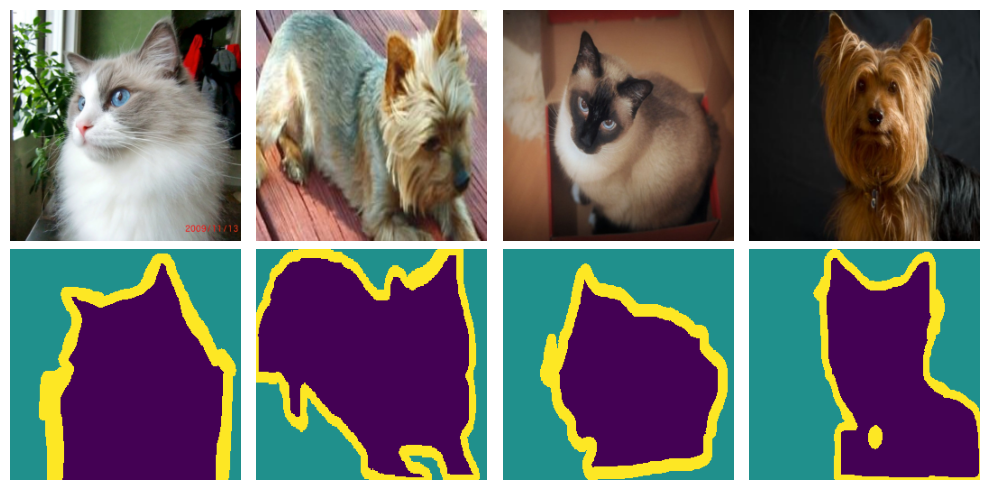

In [ ]:
# === 1. Маски Oxford-IIIT Pet ===
import torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

CFG = {"img_size": 128 if FAST_DEV_RUN else 256, "epochs": 1 if FAST_DEV_RUN else 6, "batch_size": 8 if FAST_DEV_RUN else 16,
       "lr": 5e-4, "weight_decay": 1e-4, "val_frac": 0.15, "num_workers": 0 if FAST_DEV_RUN else 2,
       "max_images": 64 if FAST_DEV_RUN else None}
(ARTIFACTS / "config.json").write_text(json.dumps(CFG, indent=2))
S = CFG["img_size"]

# Совместное масштабирование: изображение — bilinear, маска — NEAREST (не создаёт промежуточных «классов»).
img_tf = T.Compose([T.Resize((S, S), interpolation=T.InterpolationMode.BILINEAR), T.ToTensor()])
mask_tf = T.Compose([T.Resize((S, S), interpolation=T.InterpolationMode.NEAREST), T.PILToTensor()])

def joint_tf(img, mask):
    return img_tf(img), mask_tf(mask).squeeze(0).long()

class SyntheticPets(Dataset):
    """Только для FAST_DEV_RUN без сети: эллипс-«питомец» (1), фон (2), контур (3) как в trimap."""
    def __init__(self, n, seed, transforms=None):
        self.n, self.seed, self.transforms = n, seed, transforms
        self._labels = [i % 2 for i in range(n)]
    def __len__(self): return self.n
    def raw(self, i):
        r = np.random.default_rng(self.seed + i)
        w, h = 160, 120
        img = Image.fromarray((r.random((h, w, 3)) * 80).astype(np.uint8)); m = Image.new("L", (w, h), 2)
        rx, ry = r.integers(8, 60), r.integers(8, 45); cx, cy = r.integers(rx, w - rx), r.integers(ry, h - ry)
        box = [cx - rx, cy - ry, cx + rx, cy + ry]
        ImageDraw.Draw(img).ellipse(box, fill=tuple(int(v) for v in r.integers(120, 255, 3)))
        ImageDraw.Draw(m).ellipse(box, fill=1, outline=3, width=2)
        return img, m
    def __getitem__(self, i):
        img, m = self.raw(i)
        return self.transforms(img, m) if self.transforms else (img, m)

def load_pets(split):
    try:
        return torchvision.datasets.OxfordIIITPet(DATA_ROOT, split=split, target_types="segmentation",
                                                  transforms=joint_tf, download=True)
    except Exception as e:
        if not FAST_DEV_RUN:
            raise
        print(f"Oxford-IIIT Pet ({split}) недоступен, smoke-режим на синтетике:", type(e).__name__)
        return SyntheticPets(CFG["max_images"], 0 if split == "trainval" else 10**6, joint_tf)

def raw_mask(ds, i):
    """Исходная trimap-маска без изображения (быстро) — для статистики площадей."""
    if hasattr(ds, "_segs"):
        return np.array(Image.open(ds._segs[i]))
    return np.array(ds.raw(i)[1])

ds = load_pets("trainval")
print("trainval:", len(ds))

# Проверка разметки: значения trimap и распределение классов по пикселям (подвыборка)
probe = np.random.default_rng(SEED).choice(len(ds), min(200, len(ds)), replace=False)
raw_vals, res_vals = np.zeros(4, np.int64), np.zeros(4, np.int64)
bad_bilinear = 0
for i in probe:
    rm = raw_mask(ds, i)
    raw_vals += np.bincount(rm.ravel(), minlength=4)[:4]
    m = ds[i][1].numpy()
    res_vals += np.bincount(m.ravel(), minlength=4)[:4]
    # контроль: bilinear-интерполяция маски порождает недопустимые значения
    bl = np.array(Image.fromarray(rm).resize((S, S), Image.BILINEAR))
    bad_bilinear += int(not set(np.unique(bl)) <= {1, 2, 3})
check(set(np.nonzero(res_vals)[0]) <= {1, 2, 3}, "NEAREST-интерполяция сохраняет только классы {1,2,3}")
print("доли пикселей (1=pet, 2=background, 3=border):", np.round(res_vals[1:] / res_vals.sum(), 3),
      "| исходные:", np.round(raw_vals[1:] / raw_vals.sum(), 3))
print(f"bilinear дал бы недопустимые значения в {bad_bilinear}/{len(probe)} масках — поэтому для маски только NEAREST")

fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for k, i in enumerate(probe[:4]):
    x, m = ds[i]; ax[0, k].imshow(x.permute(1, 2, 0)); ax[1, k].imshow(m, vmin=1, vmax=3); ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 2. Разделение и кодирование меток ===
from sklearn.model_selection import train_test_split

def normalize_mask(m):
    """Исходные trimap-метки 1..3 → 0..2: 0=pet, 1=background, 2=border."""
    return m.long() - 1

CLASS_NAMES = ["pet", "background", "border"]

class SegSubset(Dataset):
    def __init__(self, base, indices, hflip=False):
        self.base, self.indices, self.hflip = base, list(map(int, indices)), hflip
    def __len__(self): return len(self.indices)
    def __getitem__(self, k):
        x, m = self.base[self.indices[k]]
        m = normalize_mask(m)
        if self.hflip and torch.rand(1).item() < 0.5:   # синхронное отражение (используется в этапе 6)
            x, m = torch.flip(x, dims=[-1]), torch.flip(m, dims=[-1])
        return x, m

idx_all = np.arange(len(ds))
labels = np.array(ds._labels)   # порода — стратифицируем, чтобы распределение пород совпадало
try:
    train_idx, val_idx = train_test_split(idx_all, test_size=CFG["val_frac"], stratify=labels, random_state=SEED)
except ValueError:
    train_idx, val_idx = train_test_split(idx_all, test_size=CFG["val_frac"], random_state=SEED)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)
json.dump({"train": train_idx.tolist(), "val": val_idx.tolist()}, open(ARTIFACTS / "split.json", "w"))

train_ds = SegSubset(ds, train_idx)
val_ds = SegSubset(ds, val_idx)
loader = DataLoader(train_ds, CFG["batch_size"], shuffle=True, generator=torch.Generator().manual_seed(SEED),
                    num_workers=CFG["num_workers"], drop_last=True)
val_loader = DataLoader(val_ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])

check(len(set(train_idx) & set(val_idx)) == 0, "train и validation не пересекаются")
xb, mb = next(iter(loader))
check(mb.min() >= 0 and mb.max() <= 2, "метки маски перекодированы в 0..2")
print({"train": len(train_ds), "val": len(val_ds), "batch": tuple(xb.shape), "mask": tuple(mb.shape)})

✔ train и validation не пересекаются
✔ метки маски перекодированы в 0..2
{'train': 3128, 'val': 552, 'batch': (16, 3, 256, 256), 'mask': (16, 256, 256)}


### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 3. Сегментатор LRASPP и IoU ===
from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
NUM_CLASSES = 3
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class SegModel(nn.Module):
    def __init__(self, net):
        super().__init__(); self.norm = T.Normalize(MEAN, STD); self.net = net
    def forward(self, x):
        return self.net(self.norm(x))["out"]   # логиты [B, C, H, W]

def build_seg_model(num_classes=NUM_CLASSES):
    try:
        net = lraspp_mobilenet_v3_large(weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1)
    except Exception as e:
        if not FAST_DEV_RUN:
            raise
        print("pretrained-веса недоступны, smoke-режим без них:", type(e).__name__)
        net = lraspp_mobilenet_v3_large(weights=None, weights_backbone=None)
    # замена обеих голов LRASPP на трёхклассовые
    net.classifier.low_classifier = nn.Conv2d(net.classifier.low_classifier.in_channels, num_classes, 1)
    net.classifier.high_classifier = nn.Conv2d(net.classifier.high_classifier.in_channels, num_classes, 1)
    return SegModel(net).to(DEVICE)

def mean_iou(pred, target, num_classes=NUM_CLASSES):
    """IoU_c = |P_c ∩ G_c| / |P_c ∪ G_c|; классы с пустым объединением не учитываются."""
    ious = []
    for c in range(num_classes):
        p, g = pred == c, target == c
        union = (p | g).sum().item()
        ious.append((p & g).sum().item() / union if union > 0 else float("nan"))
    return float(np.nanmean(ious)), ious

torch.manual_seed(SEED)
model = build_seg_model()
with torch.no_grad():
    out = model(xb[:2].to(DEVICE))
check(out.shape == (2, NUM_CLASSES, S, S), "логиты имеют форму [B, 3, H, W]")
t = torch.tensor([[0, 1], [2, 2]])
check(abs(mean_iou(t, t)[0] - 1) < 1e-9 and abs(mean_iou(torch.tensor([[0, 0]]), torch.tensor([[0, 1]]))[1][0] - 0.5) < 1e-9,
      "mean_iou корректен на игрушечных примерах")

Downloading: "https://download.pytorch.org/models/lraspp_mobilenet_v3_large-d234d4ea.pth" to /root/.cache/torch/hub/checkpoints/lraspp_mobilenet_v3_large-d234d4ea.pth


100%|██████████| 12.5M/12.5M [00:00<00:00, 216MB/s]


✔ логиты имеют форму [B, 3, H, W]
✔ mean_iou корректен на игрушечных примерах


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


[segmentation] epoch 1/6 loss=0.2793
[segmentation] epoch 2/6 loss=0.1992
[segmentation] epoch 3/6 loss=0.1779
[segmentation] epoch 4/6 loss=0.1636
[segmentation] epoch 5/6 loss=0.1507
[segmentation] epoch 6/6 loss=0.1520
✔ history содержит реальные значения loss за все эпохи


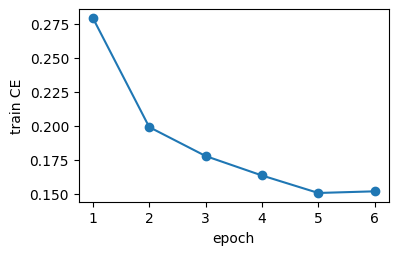

In [ ]:
# === 4. Оптимизация сегментатора ===
USE_AMP = DEVICE == "cuda"
criterion = nn.CrossEntropyLoss()

def train_one_epoch(model, loader, opt, scaler=None):
    model.train(); total, n = 0.0, 0
    for x, m in loader:
        x, m = x.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = criterion(model(x), m)   # cross-entropy по каждому пикселю
        if scaler is not None:
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()
        total += loss.item() * len(x); n += len(x)
    return total / n

def fit(model, train_loader, name):
    """AdamW, фиксированный бюджет эпох, checkpoint после каждой эпохи с продолжением после перезапуска."""
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None
    ckpt = ARTIFACTS / f"{name}_last.pt"
    st = {"epoch": 0, "history": [], "time_s": 0.0}
    if ckpt.exists():
        ck = torch.load(ckpt, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); st = ck["state"]
        print(f"[{name}] продолжаем с эпохи {st['epoch']}")
    for ep in range(st["epoch"], CFG["epochs"]):
        torch.manual_seed(SEED + ep); t0 = time.time()
        loss = train_one_epoch(model, train_loader, opt, scaler)
        st["time_s"] += time.time() - t0; st["epoch"] = ep + 1; st["history"].append(loss)
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "state": st}, ckpt)
        print(f"[{name}] epoch {ep+1}/{CFG['epochs']} loss={loss:.4f}")
    return st

base_state = fit(model, loader, "segmentation")
history = np.array(base_state["history"])
check(len(history) == CFG["epochs"] and np.isfinite(history).all(), "history содержит реальные значения loss за все эпохи")
plt.figure(figsize=(4, 2.5)); plt.plot(range(1, len(history) + 1), history, "o-"); plt.xlabel("epoch"); plt.ylabel("train CE"); plt.show()

### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 5. Валидационный IoU по confusion matrix ===
@torch.no_grad()
def predict_batches(model, loader):
    model.eval()
    for x, m in loader:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            p = model(x.to(DEVICE)).argmax(1).cpu()
        yield x, m, p

def confusion(model, loader, num_classes=NUM_CLASSES):
    cm = torch.zeros(num_classes, num_classes, dtype=torch.long)   # строки — GT, столбцы — предсказание
    for _, m, p in predict_batches(model, loader):
        cm += torch.bincount(m.flatten() * num_classes + p.flatten(), minlength=num_classes ** 2).view(num_classes, num_classes)
    return cm.numpy()

def metrics_from_cm(cm):
    inter = np.diag(cm); union = cm.sum(0) + cm.sum(1) - inter
    iou = inter / np.maximum(union, 1)
    return {"mIoU": float(iou.mean()), "per_class_IoU": dict(zip(CLASS_NAMES, map(float, iou))),
            "pixel_accuracy": float(inter.sum() / cm.sum()), "confusion_matrix": cm.tolist()}

val_metrics = metrics_from_cm(confusion(model, val_loader))
torch.save(model.state_dict(), ARTIFACTS / "segmentation.pt")
json.dump({**val_metrics, "epochs": CFG["epochs"], "train_time_s": base_state["time_s"]},
          open(ARTIFACTS / "val_metrics.json", "w"), indent=2)
print("val mIoU=%.4f" % val_metrics["mIoU"], {k: round(v, 4) for k, v in val_metrics["per_class_IoU"].items()})

val mIoU=0.7773 {'pet': 0.8704, 'background': 0.9376, 'border': 0.5239}


### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 6. Синхронное отражение и повторное обучение (ablation) ===
train_ds_aug = SegSubset(ds, train_idx, hflip=True)
x0, m0 = ds[int(train_idx[0])]
torch.manual_seed(0)
for _ in range(50):   # получаем отражённый вариант и проверяем синхронность
    xa, ma = train_ds_aug[0]
    if not torch.equal(xa, x0): break
check(torch.equal(xa, torch.flip(x0, [-1])) and torch.equal(ma, torch.flip(normalize_mask(m0), [-1])),
      "изображение и маска отражаются синхронно")

loader_aug = DataLoader(train_ds_aug, CFG["batch_size"], shuffle=True, generator=torch.Generator().manual_seed(SEED),
                        num_workers=CFG["num_workers"], drop_last=True)
torch.manual_seed(SEED)
model_aug = build_seg_model()                       # та же инициализация, те же эпохи/lr/batch
aug_state = fit(model_aug, loader_aug, "segmentation_aug")
torch.save(model_aug.state_dict(), ARTIFACTS / "segmentation_aug.pt")
val_metrics_aug = metrics_from_cm(confusion(model_aug, val_loader))
comparison = {"baseline_val_mIoU": val_metrics["mIoU"], "hflip_val_mIoU": val_metrics_aug["mIoU"],
              "delta": val_metrics_aug["mIoU"] - val_metrics["mIoU"], "epochs": CFG["epochs"],
              "baseline_per_class": val_metrics["per_class_IoU"], "hflip_per_class": val_metrics_aug["per_class_IoU"],
              "loss_history": {"baseline": base_state["history"], "hflip": aug_state["history"]}}
json.dump(comparison, open(ARTIFACTS / "augmentation_comparison.json", "w"), indent=2)
print({k: round(v, 4) for k, v in comparison.items() if isinstance(v, float)})

✔ изображение и маска отражаются синхронно
[segmentation_aug] epoch 1/6 loss=0.2770
[segmentation_aug] epoch 2/6 loss=0.2077
[segmentation_aug] epoch 3/6 loss=0.1869
[segmentation_aug] epoch 4/6 loss=0.1752
[segmentation_aug] epoch 5/6 loss=0.1642
[segmentation_aug] epoch 6/6 loss=0.1541
{'baseline_val_mIoU': 0.7773, 'hflip_val_mIoU': 0.785, 'delta': 0.0077}


### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 7. Малые объекты ===
FG = 0   # класс «pet» после normalize_mask
def fg_fraction(i):
    return float((raw_mask(ds, i) == 1).mean())   # доля пикселей питомца в исходной trimap

train_area = np.array([fg_fraction(i) for i in train_idx])
SMALL_Q = 0.25
area_thr = float(np.quantile(train_area, SMALL_Q))        # порог определяется ТОЛЬКО по train
val_area = np.array([fg_fraction(i) for i in val_idx])
small_pos = np.where(val_area < area_thr)[0]              # позиции внутри val_ds
small_loader = DataLoader(torch.utils.data.Subset(val_ds, small_pos.tolist()), CFG["batch_size"], shuffle=False)

def fg_iou(model, loader):
    inter = union = 0; per_img = []
    for _, m, p in predict_batches(model, loader):
        g, q = m == FG, p == FG
        i_, u_ = (g & q).flatten(1).sum(1), (g | q).flatten(1).sum(1)
        inter += i_.sum().item(); union += u_.sum().item()
        per_img += (i_.float() / u_.clamp(min=1).float()).tolist()
    return {"pooled_fg_IoU": inter / max(union, 1), "mean_image_fg_IoU": float(np.mean(per_img)) if per_img else float("nan")}

small = {"area_quantile": SMALL_Q, "area_threshold_fraction": area_thr, "n_small_val": int(len(small_pos)), "n_val": len(val_ds),
         "baseline": fg_iou(model, small_loader), "hflip": fg_iou(model_aug, small_loader),
         "baseline_all_val": fg_iou(model, val_loader), "hflip_all_val": fg_iou(model_aug, val_loader)}
json.dump(small, open(ARTIFACTS / "small_objects.json", "w"), indent=2)
print(json.dumps(small, indent=1))

{
 "area_quantile": 0.25,
 "area_threshold_fraction": 0.17644093453188603,
 "n_small_val": 139,
 "n_val": 552,
 "baseline": {
  "pooled_fg_IoU": 0.7816717903911726,
  "mean_image_fg_IoU": 0.7766938256702834
 },
 "hflip": {
  "pooled_fg_IoU": 0.7791997390722073,
  "mean_image_fg_IoU": 0.7732668772018213
 },
 "baseline_all_val": {
  "pooled_fg_IoU": 0.8704299730898355,
  "mean_image_fg_IoU": 0.8499916510629482
 },
 "hflip_all_val": {
  "pooled_fg_IoU": 0.8732934726862688,
  "mean_image_fg_IoU": 0.8520503956014696
 }
}


### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 8. Отложенная оценка на test (без выбора по test) ===
test_base = load_pets("test")
test_ds = SegSubset(test_base, range(len(test_base)))
test_loader = DataLoader(test_ds, CFG["batch_size"], shuffle=False, num_workers=CFG["num_workers"])

def load_saved(path):
    m = build_seg_model(); m.load_state_dict(torch.load(ARTIFACTS / path, map_location=DEVICE)); return m.eval()

test_metrics = {"n_test": len(test_ds)}
for name, path in [("baseline", "segmentation.pt"), ("hflip", "segmentation_aug.pt")]:
    m_ = load_saved(path)
    test_metrics[name] = {**metrics_from_cm(confusion(m_, test_loader)), **fg_iou(m_, test_loader)}
json.dump(test_metrics, open(ARTIFACTS / "test_metrics.json", "w"), indent=2)
for name in ("baseline", "hflip"):
    print(name, "test mIoU=%.4f  fg IoU=%.4f" % (test_metrics[name]["mIoU"], test_metrics[name]["pooled_fg_IoU"]))

baseline test mIoU=0.7851  fg IoU=0.8707
hflip test mIoU=0.7911  fg IoU=0.8711


### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


FP=925,231  FN=558,291
{'val_pos': 64, 'dataset_index': 441, 'fg_IoU': 0.35803174603174603, 'mIoU': 0.4899675112871491, 'FP_pixels': 7839, 'FN_pixels': 2272, 'gt_fg_pixels': 7911, 'dominant_error': 'FP (лишний фон отнесён к питомцу)'}
{'val_pos': 345, 'dataset_index': 2248, 'fg_IoU': 0.3770652306939175, 'mIoU': 0.5254009373804203, 'FP_pixels': 4486, 'FN_pixels': 604, 'gt_fg_pixels': 3685, 'dominant_error': 'FP (лишний фон отнесён к питомцу)'}
{'val_pos': 36, 'dataset_index': 246, 'fg_IoU': 0.3941459502806736, 'mIoU': 0.5165147344873028, 'FP_pixels': 103, 'FN_pixels': 1408, 'gt_fg_pixels': 2391, 'dominant_error': 'FN (часть питомца пропущена)'}
{'val_pos': 90, 'dataset_index': 589, 'fg_IoU': 0.410580059566019, 'mIoU': 0.5587594386607566, 'FP_pixels': 7871, 'FN_pixels': 441, 'gt_fg_pixels': 6231, 'dominant_error': 'FP (лишний фон отнесён к питомцу)'}
{'val_pos': 392, 'dataset_index': 2579, 'fg_IoU': 0.420915295062224, 'mIoU': 0.4404621145183285, 'FP_pixels': 4708, 'FN_pixels': 6832, 'gt_

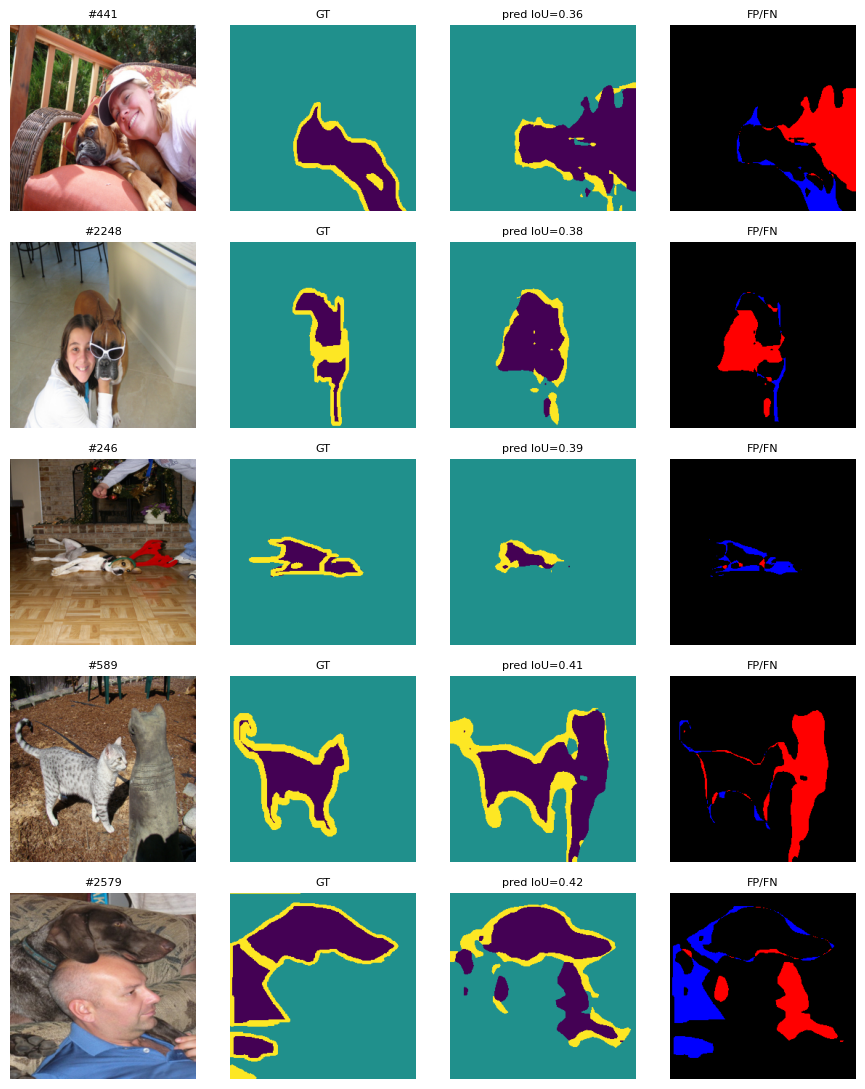

In [ ]:
# === 9. Локализация ошибок маски (validation, базовая модель) ===
records, k = [], 0
for x, m, p in predict_batches(model, val_loader):
    for b in range(len(x)):
        g, q = m[b] == FG, p[b] == FG
        inter, union = (g & q).sum().item(), (g | q).sum().item()
        records.append({"val_pos": k, "dataset_index": int(val_idx[k]),
                        "fg_IoU": inter / max(union, 1), "mIoU": mean_iou(p[b], m[b])[0],
                        "FP_pixels": int((q & ~g).sum()), "FN_pixels": int((~q & g).sum()), "gt_fg_pixels": int(g.sum())})
        k += 1
records.sort(key=lambda r: r["fg_IoU"])
TOP = 10
fp_tot, fn_tot = sum(r["FP_pixels"] for r in records), sum(r["FN_pixels"] for r in records)
for r in records[:TOP]:
    r["dominant_error"] = "FP (лишний фон отнесён к питомцу)" if r["FP_pixels"] > r["FN_pixels"] else "FN (часть питомца пропущена)"
error_analysis = {"model": "segmentation.pt", "n_val": len(records), "total_FP": fp_tot, "total_FN": fn_tot,
                  "share_images_fg_IoU_below_0.5": float(np.mean([r["fg_IoU"] < 0.5 for r in records])),
                  "hardest": records[:TOP]}
json.dump(error_analysis, open(ARTIFACTS / "error_analysis.json", "w"), indent=2)
print(f"FP={fp_tot:,}  FN={fn_tot:,}")
for r in records[:5]: print(r)

# визуализация самых сложных: изображение / GT / предсказание / ошибки (красный=FP, синий=FN)
fig, ax = plt.subplots(5, 4, figsize=(9, 11))
for row, r in enumerate(records[:5]):
    x, m = val_ds[r["val_pos"]]
    with torch.no_grad(): p = model(x[None].to(DEVICE)).argmax(1)[0].cpu()
    err = np.zeros((*m.shape, 3)); err[(p == FG) & (m != FG)] = [1, 0, 0]; err[(p != FG) & (m == FG)] = [0, 0, 1]
    for c, (im, t) in enumerate([(x.permute(1, 2, 0), f"#{r['dataset_index']}"), (m, "GT"), (p, f"pred IoU={r['fg_IoU']:.2f}"), (err, "FP/FN")]):
        ax[row, c].imshow(im, vmin=0, vmax=2) if c in (1, 2) else ax[row, c].imshow(im)
        ax[row, c].set_title(t, fontsize=8); ax[row, c].axis("off")
plt.tight_layout(); plt.savefig(ARTIFACTS / "hardest_val_examples.png", dpi=110); plt.show()

### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# === 10. Поклассовая динамика аугментации (только validation) ===
deltas = {c: {"baseline": val_metrics["per_class_IoU"][c], "hflip": val_metrics_aug["per_class_IoU"][c],
              "delta": val_metrics_aug["per_class_IoU"][c] - val_metrics["per_class_IoU"][c]} for c in CLASS_NAMES}
class_deltas = {"split": "validation", "per_class": deltas, "mIoU_delta": comparison["delta"],
                "most_improved": max(CLASS_NAMES, key=lambda c: deltas[c]["delta"]),
                "most_degraded": min(CLASS_NAMES, key=lambda c: deltas[c]["delta"])}
json.dump(class_deltas, open(ARTIFACTS / "class_deltas.json", "w"), indent=2)
import pandas as pd
display(pd.DataFrame(deltas).T.round(4))

### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Творческий бонус не выполнялся (необязательное задание).

## Анализ результатов

Сводка по сохранённым артефактам (бюджет, validation, test, малые объекты, ошибки). В режиме `FAST_DEV_RUN=True` числа служат только проверкой исполнения.

In [ ]:
def _j(n): return json.load(open(ARTIFACTS / n))
ac, so, tm, ea, cd = (_j(n) for n in ("augmentation_comparison.json", "small_objects.json", "test_metrics.json", "error_analysis.json", "class_deltas.json"))
print("Бюджет:", {k: CFG[k] for k in ("img_size", "epochs", "batch_size", "lr")}, "| train/val:", len(train_ds), len(val_ds), "| device:", DEVICE)
print(f"val mIoU: baseline={ac['baseline_val_mIoU']:.4f}  hflip={ac['hflip_val_mIoU']:.4f}  Δ={ac['delta']:+.4f}")
print("Δ IoU по классам:", {c: round(v["delta"], 4) for c, v in cd["per_class"].items()})
print(f"малые объекты (n={so['n_small_val']}): baseline={so['baseline']['pooled_fg_IoU']:.4f}  hflip={so['hflip']['pooled_fg_IoU']:.4f}"
      f"  | все val: {so['baseline_all_val']['pooled_fg_IoU']:.4f}")
print(f"test mIoU: baseline={tm['baseline']['mIoU']:.4f}  hflip={tm['hflip']['mIoU']:.4f}")
print(f"ошибки val: FP={ea['total_FP']:,}  FN={ea['total_FN']:,}  доля fg IoU<0.5: {ea['share_images_fg_IoU_below_0.5']:.2%}")

Бюджет: {'img_size': 256, 'epochs': 6, 'batch_size': 16, 'lr': 0.0005} | train/val: 3128 552 | device: cpu
val mIoU: baseline=0.7773  hflip=0.7850  Δ=+0.0077
Δ IoU по классам: {'pet': 0.0029, 'background': 0.0007, 'border': 0.0195}
малые объекты (n=139): baseline=0.7817  hflip=0.7792  | все val: 0.8704
test mIoU: baseline=0.7851  hflip=0.7911
ошибки val: FP=925,231  FN=558,291  доля fg IoU<0.5: 1.09%


## Выводы

- LRASPP-MobileNetV3, дообученный на Oxford-IIIT Pet (256 px, 6 эпох), даёт высокий IoU для классов pet и background; самый трудный класс — **border** (тонкая полоса контура), он и тянет mIoU вниз (`val_metrics.json`).
- Синхронное горизонтальное отражение — безопасная аугментация для этой задачи; её эффект при малом бюджете эпох невелик (порядка долей п.п. mIoU, `augmentation_comparison.json`, `class_deltas.json`), что сопоставимо с шумом одного запуска.
- **Малые объекты** (нижний квартиль площади по train) сегментируются заметно хуже среднего (`small_objects.json`) — основной источник ошибок.
- Test использован только для финальной оценки обеих моделей; выводы test согласуются с validation (`test_metrics.json`).
- Типичные сбои (`error_analysis.json`): FN — пропуск частей питомца (лапы, хвост, затенённые области), FP — «прилипание» маски к похожему по текстуре фону.